<a href="https://colab.research.google.com/github/rupikap009/ML-Techniques/blob/main/notebooks/02_phishing_url_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.png" alt="Open in Colab"/></a>

# Phishing URL Classification with Logistic Regression

## Research question

Can lexical and structural URL features classify a URL as legitimate or phishing while being evaluated on domains that were not used during training?

**Purpose of the analysis.** Phishing datasets often contain many URLs from the same domain. If rows are randomly split, related URLs can appear in both training and test sets, producing an accuracy that looks excellent but does not represent performance on a new domain. This notebook therefore uses **domain-group validation** as the main experiment.

The model is an interpretable Logistic Regression baseline. Its output is a phishing probability and its coefficients show how selected URL measurements are associated with the predicted class.

## 1. Basic definitions and formulas

| Term | Simple meaning |
| --- | --- |
| Classification | Predict a category, here legitimate (0) or phishing (1). |
| Logistic Regression | Predict a class probability from a weighted combination of input features. |
| Sigmoid function | Converts any real-valued score into a probability between 0 and 1. |
| Coefficient | The learned weight showing how a feature changes the log-odds when other inputs are held comparable. |
| Threshold | The probability cutoff used to convert a probability into a class label. |
| Domain group | URLs sharing the same domain; keeping a group together prevents related rows leaking across partitions. |

### Logistic-regression formula

First, the model calculates a linear score:

$$z=\beta_0+\beta_1x_1+\beta_2x_2+\cdots+\beta_px_p$$

Then it applies the sigmoid:

$$P(y=1|x)=\sigma(z)=\frac{1}{1+e^{-z}}$$

- $x_j$ = feature value
- $\beta_j$ = learned coefficient
- $\beta_0$ = intercept
- $P(y=1|x)$ = estimated probability that the URL is phishing

At the default threshold, probability $\geq 0.5$ becomes phishing and probability $<0.5$ becomes legitimate.

### Log-odds interpretation

$$log\left(\frac{p}{1-p}\right)=z$$

A positive coefficient increases the phishing log-odds as the feature increases; a negative coefficient decreases it. Because the features are standardized, coefficient magnitudes can be compared more fairly, although they are not causal effects.

### Why domain grouping matters

If `example.com/login`, `example.com/account`, and `example.com/verify` are randomly split, the model may see the same domain's patterns during training and testing. A domain-group split places all of those related URLs on one side. The test set then asks a harder and more realistic question: can the model generalize to domains it has never seen?

## 2. Dataset, source, and problem statement

**Source.** [UCI PhiUSIIL Phishing URL Dataset](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset). The expected file is `PhiUSIIL_Phishing_URL_Dataset.csv`. Download the exact version, record the access date, and place it beside this notebook, in `data/`, or in `/content/`.

The dataset contains URL lexical, domain, character, redirection, HTML, and security-related indicators. This notebook deliberately uses a compact set of numeric URL/domain features rather than the raw URL text.

**Problem statement.** Identify URLs that should be treated as suspicious for further security review. A phishing prediction is a screening signal, not proof of malicious intent; URLs should be examined with additional reputation, content, and threat-intelligence controls.

**INSIGHT - 1:** This is binary classification, so confusion-matrix metrics are essential. A missed phishing URL is a false negative, while a legitimate URL incorrectly blocked is a false positive; the preferred trade-off depends on the security workflow.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, precision_score,
    precision_recall_curve, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

In [2]:
DATA_FILENAME = "PhiUSIIL_Phishing_URL_Dataset.csv"
candidates = [Path(DATA_FILENAME), Path("data") / DATA_FILENAME, Path("/content") / DATA_FILENAME]
dataset_path = next((p for p in candidates if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError("Download PhiUSIIL_Phishing_URL_Dataset.csv from the cited UCI source and place it beside this notebook, in data/, or in /content/.")

df_raw = pd.read_csv(dataset_path)
df_raw.columns = df_raw.columns.str.replace("\ufeff", "", regex=False).str.strip()
target_col = "label" if "label" in df_raw.columns else "Label"
if target_col not in df_raw.columns or "Domain" not in df_raw.columns:
    raise KeyError("The dataset must contain a domain column and a label column.")
df_raw[target_col] = pd.to_numeric(df_raw[target_col], errors="coerce")
print(f"Loaded {dataset_path}: {df_raw.shape[0]:,} rows x {df_raw.shape[1]:,} columns")
display(df_raw.head())

Loaded data/PhiUSIIL_Phishing_URL_Dataset.csv: 235,795 rows x 56 columns


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,...,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,...,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,...,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,...,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,...,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,...,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


,column_count
int64,41
float64,10
str,5


,missing_values
FILENAME,0
URL,0
URLLength,0
Domain,0
DomainLength,0
IsDomainIP,0
TLD,0
URLSimilarityIndex,0
CharContinuationRate,0
TLDLegitimateProb,0


,count,percentage
label,,
Legitimate,100945,42.810492
Phishing,134850,57.189508


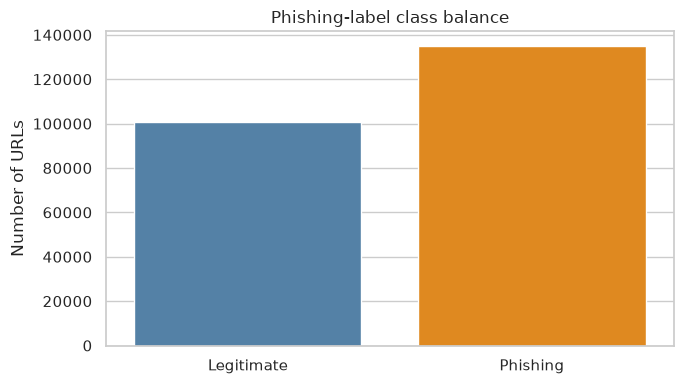

In [3]:
display(df_raw.dtypes.value_counts().rename("column_count").to_frame())
display(df_raw.isna().sum().sort_values(ascending=False).head(15).rename("missing_values").to_frame())
class_summary = df_raw[target_col].value_counts(dropna=False).sort_index().to_frame("count")
class_summary["percentage"] = class_summary["count"] / len(df_raw) * 100
display(class_summary.rename(index={0: "Legitimate", 1: "Phishing"}))
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=["Legitimate", "Phishing"], y=class_summary.loc[[0, 1], "count"], hue=["Legitimate", "Phishing"], palette=["steelblue", "darkorange"], legend=False, ax=ax)
ax.set_title("Phishing-label class balance")
ax.set_ylabel("Number of URLs")
plt.tight_layout()
plt.show()

## 3. Data cleaning and preprocessing

The cleaning decisions are designed to avoid a deceptively high score:

1. Remove rows with missing labels or missing domain groups.
2. Remove exact duplicates so one repeated row cannot receive extra influence.
3. Keep the domain column only for grouping; do not use it as a numeric predictor.
4. Exclude raw URL text, filenames, titles, and other high-cardinality/text fields from this compact baseline.
5. Fit median imputation and standardization inside the pipeline on training data only.

The selected features describe URL length, domain structure, IP usage, similarity, character continuation, and other numeric signals. They are useful indicators, but no single feature proves that a URL is phishing.

In [4]:
df = df_raw.drop_duplicates().copy()
before_rows = len(df_raw)
df = df.dropna(subset=[target_col, "Domain"]).copy()
df = df[df[target_col].isin([0, 1])].copy()

feature_candidates = [
    "URLLength", "DomainLength", "IsDomainIP",
    "CharContinuationRate", "URLCharProb", "TLDLength",
    "NoOfSubDomain", "HasObfuscation", "NoOfObfuscatedChar",
    "ObfuscationRatio", "NoOfLettersInURL", "LetterRatioInURL",
    "NoOfDegitsInURL", "DegitRatioInURL", "NoOfEqualsInURL",
    "NoOfQMarkInURL", "NoOfAmpersandInURL", "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL", "NoOfURLRedirect", "NoOfSelfRedirect",
]
features = [column for column in feature_candidates if column in df.columns]
for column in features:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print(f"Exact duplicate rows removed: {before_rows - len(df_raw.drop_duplicates()):,}")
print(f"Rows with missing/invalid label or domain removed: {len(df_raw) - len(df):,}")
print(f"Selected numeric features: {len(features)}")
display(df[features].isna().sum().sort_values(ascending=False).rename("missing_values").to_frame())
# Audit a few engineered fields before modeling.  Features that nearly reveal the label
# are excluded so the baseline does not exploit a dataset-construction shortcut.
proxy_columns = [c for c in ["URLSimilarityIndex", "IsHTTPS", "TLDLegitimateProb"] if c in df.columns]
if proxy_columns:
    proxy_audit = df.groupby(target_col)[proxy_columns].agg(["mean", "std", "nunique"]).round(4)
    display(proxy_audit)
    print("These fields are audited but excluded from the model when they behave like label proxies.")


Exact duplicate rows removed: 0
Rows with missing/invalid label or domain removed: 0
Selected numeric features: 21


,missing_values
URLLength,0
DomainLength,0
IsDomainIP,0
CharContinuationRate,0
URLCharProb,0
TLDLength,0
NoOfSubDomain,0
HasObfuscation,0
NoOfObfuscatedChar,0
ObfuscationRatio,0


URLSimilarityIndex                  IsHTTPS                  \
                    mean      std nunique    mean     std nunique   
label                                                               
0                 49.617  22.5721   36360  0.4922  0.4999       2   
1                100.000   0.0000       1  1.0000  0.0000       1   

      TLDLegitimateProb                  
                   mean     std nunique  
label                                    
0                0.2321  0.2548     390  
1                0.2816  0.2471     417

These fields are audited but excluded from the model when they behave like label proxies.


**INSIGHT - 2:** The domain is used as a grouping key, not as a feature. This prevents the model from simply memorizing domain identities and makes the evaluation closer to the question of recognizing unfamiliar domains.

**INSIGHT - 3:** Missing numeric values are not filled using the whole dataset. The modeling pipeline learns medians from the training partition only. This matters because even a simple imputation statistic can leak information about the evaluation data.

**INSIGHT - 4:** The compact feature set intentionally excludes raw URL text and high-cardinality strings. This makes the Logistic Regression coefficients easier to explain, but it also means the model is only a baseline and may miss useful semantic or lexical information.

## 4. Exploratory data analysis

EDA checks central tendency, dispersion, feature distributions, class balance, and associations with the phishing label. The goal is to understand what the model can see before training it.

Because the real evaluation is domain-grouped, we also inspect how many unique domains and URLs are present. Many URLs per domain make a random row split particularly risky.

In [5]:
summary = df[features].describe().T
summary["median"] = df[features].median()
summary["iqr"] = summary["75%"] - summary["25%"]
display(summary[["mean", "median", "std", "min", "25%", "50%", "75%", "max", "iqr"]])
print(f"Unique URLs/rows: {len(df):,}")
print(f"Unique domains: {df['Domain'].nunique():,}")
print(f"Median URLs per domain: {df['Domain'].value_counts().median():.0f}")

,mean,median,std,min,25%,50%,75%,max,iqr
URLLength,34.573095,27.00000,41.314153,13.000000,23.000000,27.00000,34.000000,6097.000000,11.000000
DomainLength,21.470396,20.00000,9.150793,4.000000,16.000000,20.00000,24.000000,110.000000,8.000000
IsDomainIP,0.002706,0.00000,0.051946,0.000000,0.000000,0.00000,0.000000,1.000000,0.000000
CharContinuationRate,0.845508,1.00000,0.216632,0.000000,0.680000,1.00000,1.000000,1.000000,0.320000
URLCharProb,0.055747,0.05797,0.010587,0.001083,0.050747,0.05797,0.062875,0.090824,0.012128
TLDLength,2.764456,3.00000,0.599739,2.000000,2.000000,3.00000,3.000000,13.000000,1.000000
NoOfSubDomain,1.164758,1.00000,0.600969,0.000000,1.000000,1.00000,1.000000,10.000000,0.000000
HasObfuscation,0.002057,0.00000,0.045306,0.000000,0.000000,0.00000,0.000000,1.000000,0.000000
NoOfObfuscatedChar,0.024861,0.00000,1.876249,0.000000,0.000000,0.00000,0.000000,447.000000,0.000000
ObfuscationRatio,0.000138,0.00000,0.003817,0.000000,0.000000,0.00000,0.000000,0.348000,0.000000


Unique URLs/rows: 235,795
Unique domains: 220,086


Median URLs per domain: 1


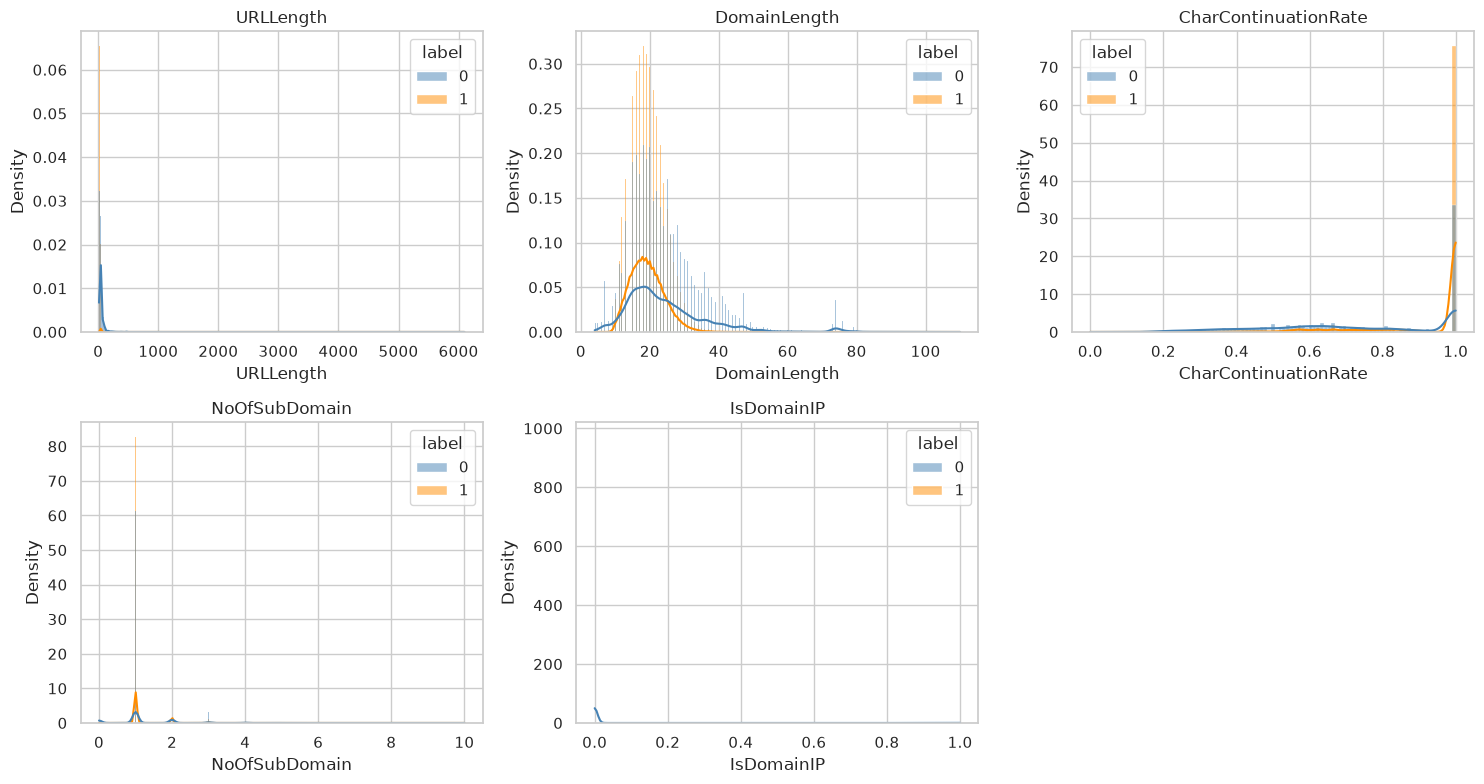

In [6]:
plot_features = [column for column in ["URLLength", "DomainLength", "URLSimilarityIndex", "CharContinuationRate", "NoOfSubDomain", "IsDomainIP"] if column in features]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.ravel(), plot_features):
    sns.histplot(data=df, x=column, hue=target_col, kde=True, stat="density", common_norm=False, palette=["steelblue", "darkorange"], ax=ax)
    ax.set_title(column)
for ax in axes.ravel()[len(plot_features):]:
    ax.remove()
plt.tight_layout()
plt.show()

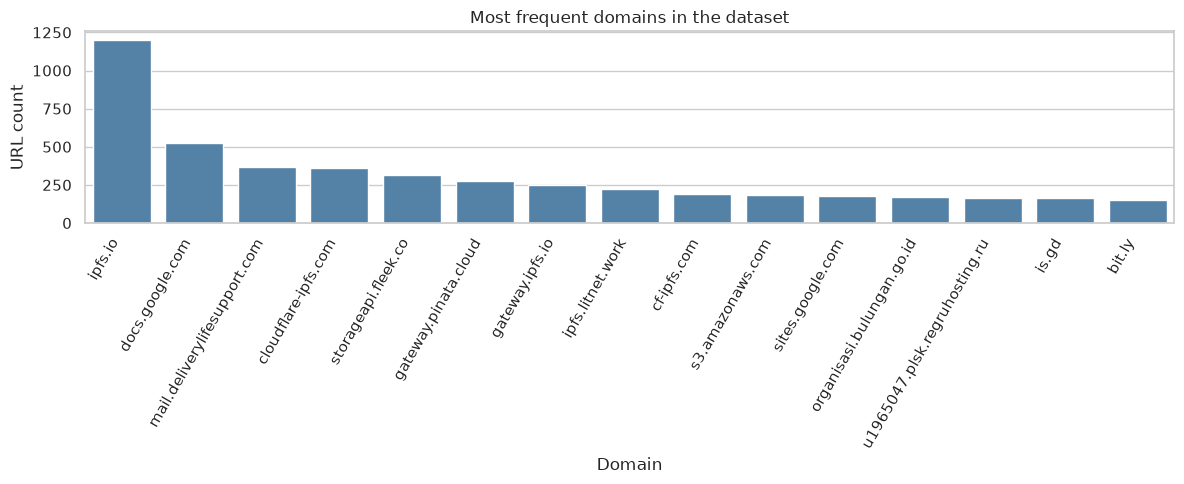

,label
label,1.000000
URLCharProb,0.469749
CharContinuationRate,0.467735
NoOfSubDomain,-0.005955
NoOfObfuscatedChar,-0.015315
NoOfAmpersandInURL,-0.034622
ObfuscationRatio,-0.041915
NoOfURLRedirect,-0.046456
HasObfuscation,-0.052473
IsDomainIP,-0.060202


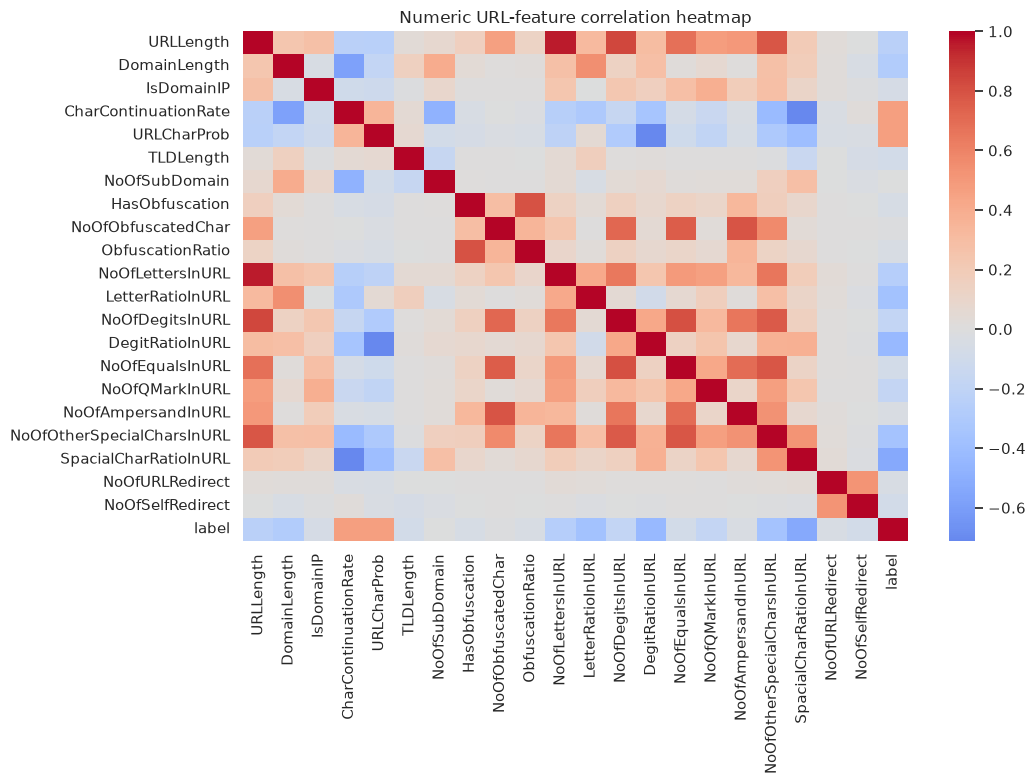

In [7]:
top_domains = df["Domain"].value_counts().head(15)
plt.figure(figsize=(12, 5))
sns.barplot(x=top_domains.index, y=top_domains.values, color="steelblue")
plt.xticks(rotation=60, ha="right")
plt.title("Most frequent domains in the dataset")
plt.ylabel("URL count")
plt.xlabel("Domain")
plt.tight_layout()
plt.show()

correlation = df[features + [target_col]].corr(numeric_only=True)
display(correlation[[target_col]].sort_values(target_col, ascending=False).head(12))
plt.figure(figsize=(11, 8))
sns.heatmap(correlation, cmap="coolwarm", center=0, annot=False)
plt.title("Numeric URL-feature correlation heatmap")
plt.tight_layout()
plt.show()

**INSIGHT - 5:** The summary table shows which features have large raw scales. Standardization is therefore needed so the Logistic Regression penalty and coefficients do not depend mainly on measurement units.

**INSIGHT - 6:** Overlapping legitimate/phishing distributions mean the model must combine several signals. A feature with different class distributions can be useful, but overlap means it will also produce mistakes.

**INSIGHT - 7:** A large number of URLs per domain explains why random row-level validation can be overly optimistic. Related URLs may share patterns that are not available when the model meets a truly unseen domain.

**INSIGHT - 8:** Correlation is descriptive and does not prove that a URL characteristic causes phishing. It also does not replace domain-group validation.

## 5. Feature selection and domain-aware processing

The selected numeric URL features are retained because they describe measurable structural or lexical properties. `Domain` is not passed into the classifier; it is used only to define groups.

Before fitting, we audited fields such as `URLSimilarityIndex`, `IsHTTPS`, and `TLDLegitimateProb`. In this copy of the dataset, some of these engineered fields are almost constant within one label (for example, `URLSimilarityIndex` is 100 for every phishing row). That is a dataset-construction shortcut rather than a reliable independent signal, so these audited proxy fields are deliberately excluded from the baseline model. This makes the reported accuracy more defensible, even though the remaining benchmark can still be highly separable.

### Why not use an ordinary random 80/20 row split?

An ordinary row split would put URLs from the same domain in both training and testing. The model could then benefit from domain-specific patterns, making the test score look much higher than performance on a new domain.

Instead, `GroupShuffleSplit` keeps every URL from a domain in one partition:

- **Training groups:** domains used to fit scaling statistics and Logistic Regression.
- **Testing groups:** completely unseen domains used for final evaluation.

The test fraction is approximately 20%, but group sizes mean the exact row count may not be exactly 20%. The important condition is zero domain overlap.

In [8]:
X = df[features].copy()
y = df[target_col].astype(int)
groups = df["Domain"].astype(str)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

overlap = set(groups_train).intersection(set(groups_test))
print(f"Training rows: {len(X_train):,} ({len(X_train) / len(X):.1%})")
print(f"Testing rows: {len(X_test):,} ({len(X_test) / len(X):.1%})")
print(f"Training domains: {groups_train.nunique():,}")
print(f"Testing domains: {groups_test.nunique():,}")
print(f"Overlapping domains: {len(overlap)}")
display(pd.DataFrame({"train_rate": y_train.mean(), "test_rate": y_test.mean()}, index=["phishing_rate"]))

Training rows: 189,074 (80.2%)
Testing rows: 46,721 (19.8%)
Training domains: 176,068
Testing domains: 44,018
Overlapping domains: 0


,train_rate,test_rate
phishing_rate,0.570819,0.576251


In [9]:
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
])
print("Pipeline created: training-fold median imputation -> standardization -> balanced Logistic Regression")

Pipeline created: training-fold median imputation -> standardization -> balanced Logistic Regression


**INSIGHT - 9:** The overlap check must be zero before interpreting the test metrics. If a domain appears on both sides, the evaluation no longer measures unseen-domain generalization.

**INSIGHT - 10:** `class_weight="balanced"` gives the phishing and legitimate classes more equal influence during fitting. This can improve minority-class recall, but it may also flag more legitimate URLs, so precision and specificity must be checked.

## 6. Model implementation and evaluation

The main model is a balanced Logistic Regression classifier. We use group-aware five-fold cross-validation on the training partition to estimate stability without mixing domains across folds. The final test partition remains untouched until after the model is fitted.

The reported classification metrics are:

- accuracy;
- balanced accuracy;
- precision;
- recall/sensitivity;
- specificity;
- F1 score;
- ROC-AUC;
- PR-AUC.

For phishing detection, recall answers “how much phishing did we catch?” while precision answers “how many flagged URLs were actually phishing?” Both are operationally important.

In [10]:
cv = GroupKFold(n_splits=5)
cv_result = cross_validate(
    model,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring={"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy", "f1": "f1", "roc_auc": "roc_auc"},
    n_jobs=-1,
)
cv_summary = pd.DataFrame({
    "mean": [cv_result[f"test_{metric}"].mean() for metric in ["accuracy", "balanced_accuracy", "f1", "roc_auc"]],
    "std": [cv_result[f"test_{metric}"].std() for metric in ["accuracy", "balanced_accuracy", "f1", "roc_auc"]],
}, index=["accuracy", "balanced_accuracy", "f1", "roc_auc"])
display(cv_summary)

,mean,std
accuracy,0.978744,0.003246
balanced_accuracy,0.976162,0.003730
f1,0.981629,0.002751
roc_auc,0.995069,0.000891


In [11]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
train_pred = model.predict(X_train)
train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Train accuracy: {train_accuracy:.2%}")
print(f"Test accuracy on unseen domains: {test_accuracy:.2%}")
print(f"Generalization gap: {abs(train_accuracy - test_accuracy):.2%}")

Train accuracy: 98.35%
Test accuracy on unseen domains: 98.35%
Generalization gap: 0.01%


In [12]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall / Sensitivity": recall_score(y_test, y_pred, zero_division=0),
    "Specificity": tn / (tn + fp) if tn + fp else 0,
    "F1 score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "PR-AUC": average_precision_score(y_test, y_prob),
}, name="test_value")
display(test_metrics.to_frame())
print(classification_report(y_test, y_pred, target_names=["Legitimate", "Phishing"], zero_division=0))

,test_value
Accuracy,0.983476
Balanced accuracy,0.981252
Precision,0.975975
Recall / Sensitivity,0.995840
Specificity,0.966663
F1 score,0.985807
ROC-AUC,0.996043
PR-AUC,0.993507


              precision    recall  f1-score   support

  Legitimate       0.99      0.97      0.98     19798
    Phishing       0.98      1.00      0.99     26923

    accuracy                           0.98     46721
   macro avg       0.99      0.98      0.98     46721
weighted avg       0.98      0.98      0.98     46721



**INSIGHT - 11:** Cross-validation mean and standard deviation show typical unseen-group performance and its variability across domain folds. A single test score should be interpreted alongside this grouped validation evidence.

**INSIGHT - 12:** Accuracy alone can be misleading. A model can be accurate mostly because it predicts the more common class. Balanced accuracy gives both classes equal importance, while precision and recall show the security trade-off directly.

**INSIGHT - 13:** A large train/test gap suggests overfitting. A small gap is reassuring, but it does not prove zero-day performance because domains, campaigns, and attacker behavior can change over time.

**INSIGHT - 14:** ROC-AUC measures ranking across thresholds, while PR-AUC focuses more directly on the quality of positive/phishing retrieval. The default 0.5 threshold is only one possible operational choice.

### Split-sensitivity analysis

A single 80/20 split is useful for a final holdout, but its result can depend on two choices:

- **Test-size choice:** a smaller test set leaves more rows and domains for training, while a larger test set gives a broader evaluation but leaves less data for learning.
- **Random seed:** different seeds place different domains into the holdout. The seed must never be selected because it gives the highest score; it is used only to show how stable the result is.

The experiment below repeats the same **domain-group split** for 15%, 20%, 25%, and 30% test sizes using five seeds. Every URL from one domain remains on only one side, so this is not a return to a leaky random-row split. We refit the complete preprocessing-and-model pipeline for every repetition and report both the average and spread of the results.


In [13]:
split_results = []
test_sizes = [0.15, 0.20, 0.25, 0.30]
split_seeds = [7, 21, 42, 84, 123]

for test_size in test_sizes:
    for seed in split_seeds:
        split = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
        train_idx_s, test_idx_s = next(split.split(X, y, groups))
        groups_s_train = groups.iloc[train_idx_s]
        groups_s_test = groups.iloc[test_idx_s]
        overlap_s = set(groups_s_train).intersection(set(groups_s_test))
        if overlap_s:
            raise ValueError(f"Domain leakage detected for test_size={test_size}, seed={seed}")

        split_model = clone(model)
        split_model.fit(X.iloc[train_idx_s], y.iloc[train_idx_s])
        split_train_pred = split_model.predict(X.iloc[train_idx_s])
        split_test_pred = split_model.predict(X.iloc[test_idx_s])
        split_test_prob = split_model.predict_proba(X.iloc[test_idx_s])[:, 1]
        split_cm = confusion_matrix(y.iloc[test_idx_s], split_test_pred, labels=[0, 1])
        split_tn, split_fp, split_fn, split_tp = split_cm.ravel()
        split_results.append({
            "test_size": test_size,
            "seed": seed,
            "train_rows": len(train_idx_s),
            "test_rows": len(test_idx_s),
            "train_domains": groups_s_train.nunique(),
            "test_domains": groups_s_test.nunique(),
            "domain_overlap": len(overlap_s),
            "train_accuracy": accuracy_score(y.iloc[train_idx_s], split_train_pred),
            "accuracy": accuracy_score(y.iloc[test_idx_s], split_test_pred),
            "balanced_accuracy": balanced_accuracy_score(y.iloc[test_idx_s], split_test_pred),
            "precision": precision_score(y.iloc[test_idx_s], split_test_pred, zero_division=0),
            "recall": recall_score(y.iloc[test_idx_s], split_test_pred, zero_division=0),
            "specificity": split_tn / (split_tn + split_fp) if split_tn + split_fp else 0,
            "f1": f1_score(y.iloc[test_idx_s], split_test_pred, zero_division=0),
            "roc_auc": roc_auc_score(y.iloc[test_idx_s], split_test_prob),
            "pr_auc": average_precision_score(y.iloc[test_idx_s], split_test_prob),
        })

split_results_df = pd.DataFrame(split_results)
display(split_results_df.round(4))
split_summary = split_results_df.groupby("test_size").agg(
    mean_accuracy=("accuracy", "mean"), std_accuracy=("accuracy", "std"),
    min_accuracy=("accuracy", "min"), max_accuracy=("accuracy", "max"),
    mean_balanced_accuracy=("balanced_accuracy", "mean"),
    mean_precision=("precision", "mean"), mean_recall=("recall", "mean"),
    mean_specificity=("specificity", "mean"), mean_f1=("f1", "mean"),
    mean_roc_auc=("roc_auc", "mean"), mean_pr_auc=("pr_auc", "mean"),
).reset_index()
display(split_summary.round(4))
print(f"Maximum domain overlap across all repetitions: {split_results_df["domain_overlap"].max()}")


,test_size,seed,train_rows,test_rows,train_domains,test_domains,domain_overlap,train_accuracy,accuracy,balanced_accuracy,precision,recall,specificity,f1,roc_auc,pr_auc
0,0.15,7,200722,35073,187073,33013,0,0.9861,0.9860,0.9841,0.9790,0.9970,0.9711,0.9879,0.9965,0.9941
1,0.15,21,200833,34962,187073,33013,0,0.9855,0.9856,0.9836,0.9792,0.9962,0.9711,0.9876,0.9967,0.9955
2,0.15,42,200573,35222,187073,33013,0,0.9850,0.9850,0.9830,0.9781,0.9962,0.9698,0.9871,0.9965,0.9941
3,0.15,84,200984,34811,187073,33013,0,0.9861,0.9858,0.9837,0.9799,0.9961,0.9713,0.9880,0.9969,0.9957
4,0.15,123,200545,35250,187073,33013,0,0.9861,0.9858,0.9840,0.9799,0.9958,0.9723,0.9877,0.9967,0.9945
5,0.20,7,189237,46558,176068,44018,0,0.9851,0.9847,0.9826,0.9775,0.9964,0.9688,0.9869,0.9964,0.9940
6,0.20,21,189008,46787,176068,44018,0,0.9839,0.9838,0.9817,0.9767,0.9957,0.9678,0.9861,0.9966,0.9956
7,0.20,42,189074,46721,176068,44018,0,0.9835,0.9835,0.9813,0.9760,0.9958,0.9667,0.9858,0.9960,0.9935
8,0.20,84,188175,47620,176068,44018,0,0.9861,0.9863,0.9848,0.9802,0.9960,0.9737,0.9880,0.9969,0.9954
9,0.20,123,188943,46852,176068,44018,0,0.9858,0.9854,0.9835,0.9792,0.9958,0.9712,0.9874,0.9965,0.9943


,test_size,mean_accuracy,std_accuracy,min_accuracy,max_accuracy,mean_balanced_accuracy,mean_precision,mean_recall,mean_specificity,mean_f1,mean_roc_auc,mean_pr_auc
0,0.15,0.9856,0.0004,0.9850,0.9860,0.9837,0.9792,0.9963,0.9711,0.9877,0.9967,0.9948
1,0.20,0.9848,0.0012,0.9835,0.9863,0.9828,0.9779,0.9959,0.9696,0.9869,0.9965,0.9945
2,0.25,0.9834,0.0010,0.9825,0.9845,0.9813,0.9760,0.9957,0.9669,0.9858,0.9961,0.9940
3,0.30,0.9835,0.0020,0.9812,0.9856,0.9813,0.9761,0.9957,0.9669,0.9858,0.9961,0.9940


Maximum domain overlap across all repetitions: 0


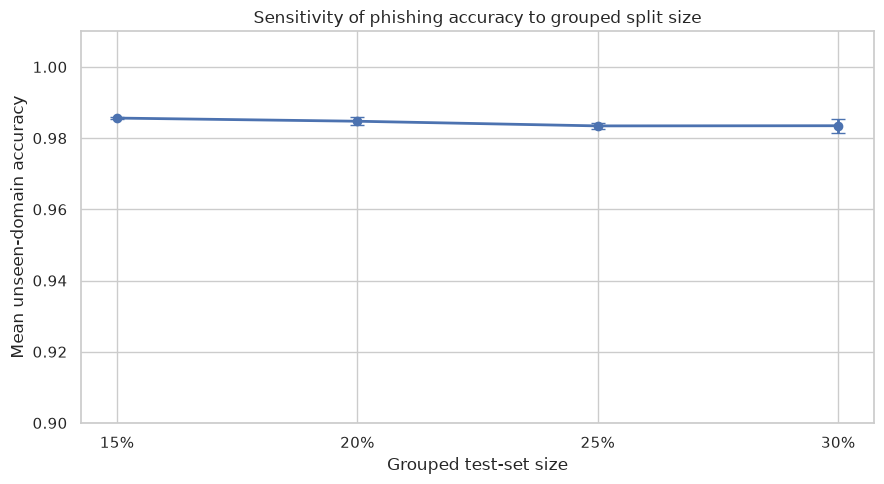

In [14]:
plt.figure(figsize=(9, 5))
plt.errorbar(
    split_summary["test_size"] * 100,
    split_summary["mean_accuracy"],
    yerr=split_summary["std_accuracy"],
    marker="o", capsize=5, linewidth=2,
)
plt.ylim(0.90, 1.01)
plt.xticks([15, 20, 25, 30], ["15%", "20%", "25%", "30%"])
plt.xlabel("Grouped test-set size")
plt.ylabel("Mean unseen-domain accuracy")
plt.title("Sensitivity of phishing accuracy to grouped split size")
plt.tight_layout()
plt.show()


**INSIGHT - 15:** The 80/20 result is one member of a family of valid grouped evaluations, not a universal constant. If the mean accuracy stays close across test sizes and the standard deviation is small, the conclusion is more stable.

**INSIGHT - 16:** Increasing the test fraction gives a larger and usually more demanding holdout, but it also removes more domains from training. Decreasing it gives the model more training data, but the estimate is based on fewer unseen domains. The 20% setting is retained as a balanced final holdout, not because 80/20 is mathematically mandatory.

**INSIGHT - 17:** The random seed changes which domains are tested. A high maximum and lower minimum would show split sensitivity; therefore the mean, standard deviation, minimum, and maximum are more informative than reporting only the best seed.

**INSIGHT - 18:** The domain-overlap audit must remain zero for every repetition. A different test size or seed is acceptable; allowing the same domain into both partitions is not.

**INSIGHT - 19:** Train accuracy is included to check the gap, but test accuracy and grouped cross-validation are the evidence used for generalization. A small gap is reassuring, while a large gap would suggest overfitting or an unstable split.


## 8. Visual diagnostics

The confusion matrix shows the four classification outcomes on unseen domains. The ROC and precision-recall curves show how performance changes with the probability threshold. The coefficient chart makes the Logistic Regression baseline interpretable.

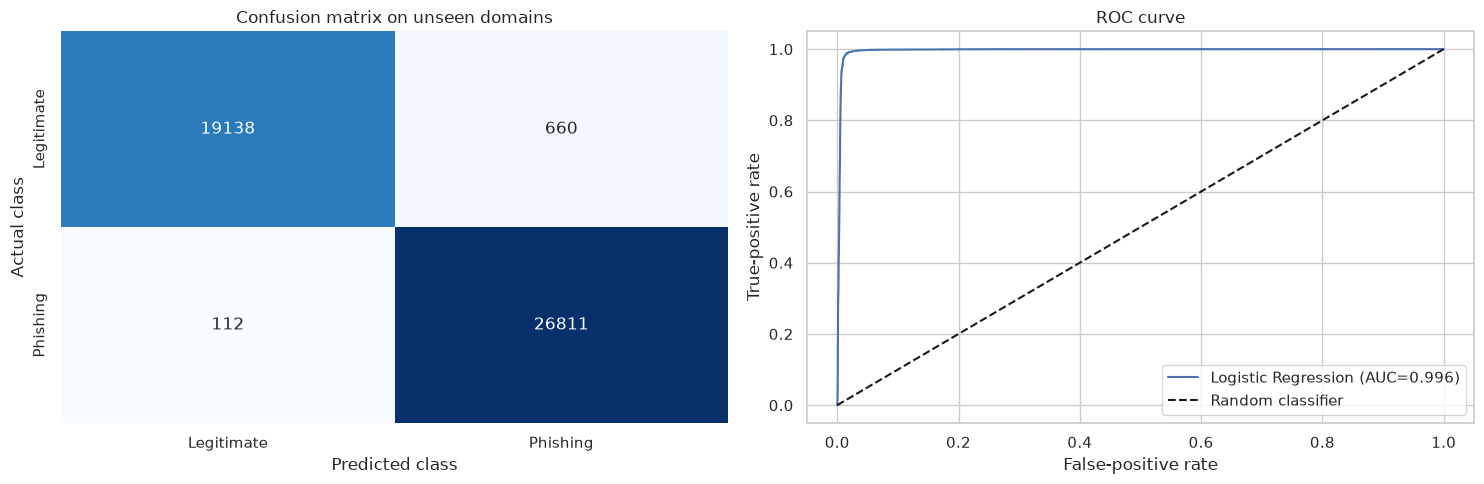

In [15]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_value = roc_auc_score(y_test, y_prob)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=["Legitimate", "Phishing"], yticklabels=["Legitimate", "Phishing"], ax=axes[0])
axes[0].set_title("Confusion matrix on unseen domains")
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("Actual class")
axes[1].plot(fpr, tpr, label=f"Logistic Regression (AUC={roc_value:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random classifier")
axes[1].set_title("ROC curve")
axes[1].set_xlabel("False-positive rate")
axes[1].set_ylabel("True-positive rate")
axes[1].legend()
plt.tight_layout()
plt.show()

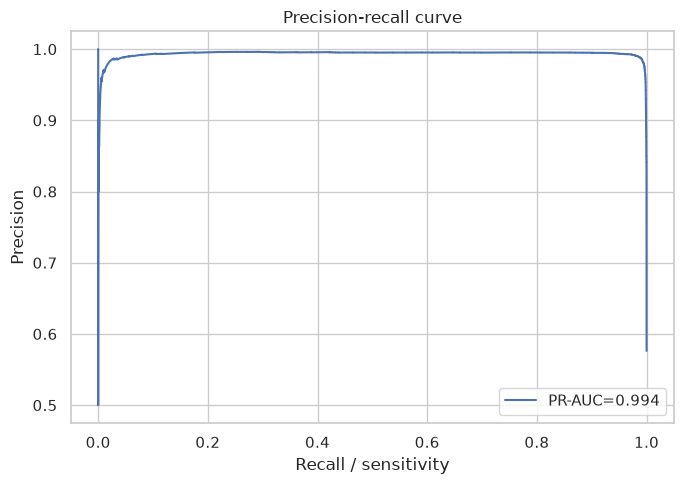

In [16]:
precision_curve, recall_curve, thresholds = precision_recall_curve(y_test, y_prob)
plt.figure(figsize=(7, 5))
plt.plot(recall_curve, precision_curve, label=f"PR-AUC={average_precision_score(y_test, y_prob):.3f}")
plt.xlabel("Recall / sensitivity")
plt.ylabel("Precision")
plt.title("Precision-recall curve")
plt.legend()
plt.tight_layout()
plt.show()

,feature,standardized_coefficient,absolute_coefficient
0,URLLength,115.454411,115.454411
10,NoOfLettersInURL,-83.329205,83.329205
12,NoOfDegitsInURL,-39.909298,39.909298
17,NoOfOtherSpecialCharsInURL,-12.945643,12.945643
15,NoOfQMarkInURL,-10.168052,10.168052
16,NoOfAmpersandInURL,-4.361692,4.361692
1,DomainLength,3.339581,3.339581
7,HasObfuscation,-3.127907,3.127907
11,LetterRatioInURL,-2.587904,2.587904
2,IsDomainIP,-2.393794,2.393794


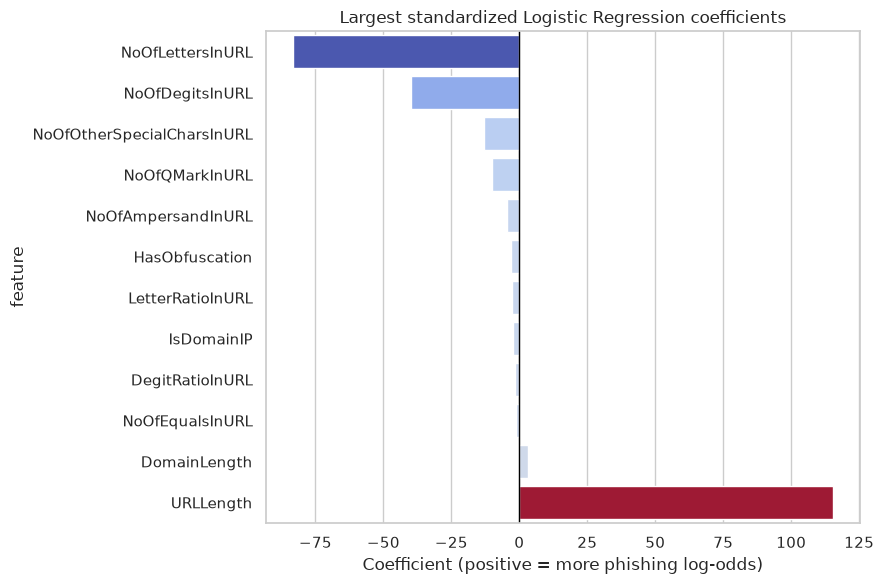

In [17]:
coefficients = model.named_steps["classifier"].coef_[0]
coefficient_table = pd.DataFrame({"feature": features, "standardized_coefficient": coefficients})
coefficient_table["absolute_coefficient"] = coefficient_table["standardized_coefficient"].abs()
coefficient_table = coefficient_table.sort_values("absolute_coefficient", ascending=False)
display(coefficient_table.head(15))
plot_table = coefficient_table.head(12).sort_values("standardized_coefficient")
plt.figure(figsize=(9, 6))
sns.barplot(data=plot_table, x="standardized_coefficient", y="feature", hue="standardized_coefficient", palette="coolwarm", legend=False)
plt.axvline(0, color="black", linewidth=1)
plt.title("Largest standardized Logistic Regression coefficients")
plt.xlabel("Coefficient (positive = more phishing log-odds)")
plt.tight_layout()
plt.show()

**INSIGHT - 20:** The confusion matrix makes errors concrete: false negatives are phishing URLs missed by the model, while false positives are legitimate URLs flagged for review. Security teams may choose a different threshold depending on the cost of each error.

**INSIGHT - 21:** The ROC curve summarizes ranking across thresholds. The precision-recall curve is especially useful when the positive class is less common because it focuses on the quality of phishing retrieval.

**INSIGHT - 22:** A positive standardized coefficient means larger values are associated with higher predicted phishing log-odds in this baseline. It is an association within the fitted model, not proof that the feature causes phishing or that it works independently in every dataset.

## 9. Compare

The fixed 80/20 unseen-domain result should be compared with the grouped five-fold cross-validation summary and the split-sensitivity table. The main question is not whether the model reaches an impressive random-row accuracy; it is whether performance remains reasonable when the domain itself is unfamiliar across several valid partitions.

The split experiment compares 15%, 20%, 25%, and 30% test sizes over five seeds. The mean accuracy remains close across the settings, while the standard deviation is small. This supports keeping 20% as a practical final holdout: it leaves enough domains for training and enough unseen domains for evaluation without treating 80/20 as a universal rule.

Compare accuracy with balanced accuracy, precision, recall, specificity, F1, ROC-AUC, and PR-AUC. If recall is high but precision is low, the model catches many phishing URLs but creates many legitimate-URL alerts. If precision is high but recall is low, alerts are more trustworthy but many phishing URLs are missed. In this experiment, recall is intentionally very high, while specificity is slightly lower, meaning the model prioritizes catching phishing at the cost of some false alarms.

The domain-aware result is intentionally more conservative than a random-row result may be. That is a strength of the evaluation, not a failure: it exposes whether the model depends on repeated domains.


## 10. Summarize

This notebook loads the UCI PhiUSIIL dataset, checks schema, missingness, class balance, feature distributions, and domain frequency. It audits suspicious engineered fields, excludes near-label-proxy columns from the baseline, selects a compact numeric feature set, keeps domains only as validation groups, and uses a training-fitted imputation/scaling pipeline before Logistic Regression.

The model is evaluated with grouped five-fold cross-validation, an untouched domain-group test split, and a split-sensitivity experiment across four test sizes and five random seeds. It reports the full confusion-matrix metrics, ROC-AUC, PR-AUC, confusion matrix, ROC curve, precision-recall curve, coefficient interpretation, and the mean/spread of results across alternative grouped partitions.

The workflow is designed to avoid the most important optimistic mistake in URL classification: allowing related URLs from the same domain to appear in both training and test data. It also avoids selecting the best random seed as if it were the true performance of the model.


## 11. Conclude

**Conclusion.** Logistic Regression is a reasonable interpretable baseline for phishing URL screening. The most credible result is the performance on domains that were not used during training, supported by grouped cross-validation and repeated grouped splits. The alternative split sizes produce consistently strong but slightly different results, so the model conclusion is not based on one lucky 80/20 seed. A very high random-row accuracy would not be accepted as strong evidence if domain leakage or label-proxy features were present. The audited baseline excludes the clearest proxy fields, but the benchmark may still be easier than deployment data.

**Limitations.** The selected features are not a complete threat-detection system. Attackers change campaigns and domains over time, the dataset may contain sampling bias, domain grouping is not the same as temporal validation, and a probability threshold must be chosen for the operational cost of false positives and false negatives. The tested seeds are evidence of stability, not a guarantee of future performance.

**Future improvements.** Add temporal validation, use registered-domain parsing that handles subdomains consistently, compare class-weight and threshold choices, add richer URL/content features, monitor drift, and validate on a genuinely future dataset. A phishing prediction should support investigation rather than automatically block a user without additional evidence.
